# Track 1, Step 4: Gene Prioritization & Phenotype Matching
**Goal:** Compare the genes disrupted by candidate variants against the child's actual documented symptoms.
**Inputs:**
- Extracted clinical HPO terms (`data/hpo_terms.txt`)
- Filtered and annotated VCF (`data/track1_step3_annotation_and_filtering.vcf.gz`)
- HPO Ontology and Gene-to-Phenotype databases (`data/hp.obo`, `data/genes_to_phenotype.txt`)

This notebook maps each variant to its affected gene, computes a phenotypic similarity score between the gene's known symptoms and the patient's symptoms, and identifies compound-heterozygous candidates. It also flags variants belonging to the MVA gene panel.


In [1]:
import sys
from pathlib import Path
import gzip
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict

# Add the 'src' directory to the path so we can import 'hpo'
REPO_ROOT = Path("..").resolve()
sys.path.insert(0, str(REPO_ROOT))

from src.hpo import Ontology, PhenotypeMatcher, load_gene_annotations

# Plotting style
sns.set_theme(style="whitegrid")


### 1. Load the Patient's HPO Terms
We read the extracted HPO terms from Step 1.


In [2]:
hpo_terms_path = REPO_ROOT / "data" / "hpo_terms.txt"
with open(hpo_terms_path, "rt") as f:
    hpo_terms = [line.strip() for line in f if line.strip()]

print(f"Loaded {len(hpo_terms)} HPO terms for the patient:")
print(hpo_terms)


Loaded 8 HPO terms for the patient:
['HP:0002859', 'HP:0000121', 'HP:0004322', 'HP:0001508', 'HP:0003202', 'HP:0001622', 'HP:0001518', 'HP:0200067']


### 2. Load the Ontology and Gene-Phenotype Annotations
We load the `hp.obo` and `genes_to_phenotype.txt` files to prepare the Resnik-style semantic similarity matcher.


In [3]:
obo_path = REPO_ROOT / "data" / "hp.obo"
g2p_path = REPO_ROOT / "data" / "genes_to_phenotype.txt"

print("Loading ontology...")
onto = Ontology.from_obo(obo_path)
print("Loading gene annotations...")
gene_terms, gene_diseases = load_gene_annotations(g2p_path, onto)

matcher = PhenotypeMatcher(onto, gene_terms)
print(f"Ontology loaded: {len(onto.parents):,} terms.")
print(f"Gene annotations loaded: {len(gene_terms):,} genes.")


Loading ontology...
Loading gene annotations...


Ontology loaded: 19,894 terms.
Gene annotations loaded: 5,277 genes.


### 3. Load MVA Panel
From our documentation and literature review, we define the MVA Tier 1 and Tier 2 genes.


In [4]:
MVA_TIER1 = {"BUB1B", "CEP57", "TRIP13", "CENATAC", "CCDC84", "MAD2L1BP", "CEP192", "SMC5", "BUB1"}
# Centrosome and SAC genes (excluding Tier 1)
MVA_TIER2 = {
    "MAD1L1", "MAD2L1", "TTK", "CDC20", "CENPE", "KNL1", "ZW10",
    "ZWILCH", "ZWINT", "SPDL1", "AURKB", "PLK1", "CENPF", "PCNT", "CDK5RAP2",
    "CEP152", "CEP135", "CEP63", "NDE1", "CENPJ", "KIF11", "ESPL1", "PTTG1",
    "SGO1", "CDCA8", "INCENP", "BIRC5", "NUF2", "NDC80", "SPC24", "SPC25",
    "MIS12", "DSN1", "ANAPC1", "CDC27", "STAG2", "SMC1A", "SMC3", "RAD21",
    "BUB3"
}

print(f"MVA Tier 1 genes: {len(MVA_TIER1)}")
print(f"MVA Tier 2 genes: {len(MVA_TIER2)}")


MVA Tier 1 genes: 9
MVA Tier 2 genes: 40


### 4. Read Annotated Variants and Calculate Phenotype Similarity
We parse the annotated VCF, group variants by gene, and compute the HPO similarity score for each gene. We also track heterozygosity to flag compound-heterozygous candidates.


In [5]:
vcf_path = REPO_ROOT / "data" / "track1_step3_annotation_and_filtering.vcf.gz"

def parse_info(info_str):
    out = {}
    for item in info_str.split(";"):
        if not item: continue
        k, sep, v = item.partition("=")
        out[k] = v if sep else True
    return out

def zygosity_from_gt(gt):
    alleles = gt.replace("|", "/").split("/")
    if any(a == "." for a in alleles) or not alleles: return "UNKNOWN"
    if all(a == "0" for a in alleles): return "HOM_REF"
    if len(set(alleles)) == 1: return "HOM_ALT"
    return "HET"

def parse_float(v):
    try:
        return float(v)
    except (TypeError, ValueError):
        return None

by_gene = defaultdict(list)
n_var = 0

with gzip.open(vcf_path, "rt", encoding="utf-8") as fh:
    for line in fh:
        if line.startswith("#"): continue
        parts = line.rstrip("\n").split("\t")
        if len(parts) < 10: continue
        
        chrom, pos, _, ref, alt, _, _, info, fmt, sample = parts[:10]
        info_d = parse_info(info)
        fmt_keys = fmt.split(":")
        sample_d = dict(zip(fmt_keys, sample.split(":")))
        
        gene = info_d.get("GENE_SYMBOL", "")
        if not gene:
            continue
            
        rec = {
            "chrom": chrom, "pos": int(pos), "ref": ref, "alt": alt,
            "gene": gene,
            "zygosity": zygosity_from_gt(sample_d.get("GT", "./.")),
            "impact": info_d.get("PUTATIVE_IMPACT", ""),
            "consequence": info_d.get("CONSEQUENCE", ""),
            "gnomad_af": parse_float(info_d.get("GNOMAD_AF")),
            "cadd_phred": parse_float(info_d.get("CADD_PHRED")),
            "revel": parse_float(info_d.get("REVEL")),
            "avi_phred": parse_float(info_d.get("AVI_PHRED")),
            "clinvar_sig": info_d.get("CLINVAR_SIG", "")
        }
        by_gene[gene].append(rec)
        n_var += 1

print(f"Processed {n_var:,} variants mapped to {len(by_gene):,} genes.")


Processed 905 variants mapped to 527 genes.


In [6]:
IMPACT_RANK = {"HIGH": 3, "MODERATE": 2, "LOW": 1, "MODIFIER": 0}

gene_rows = []
for gene, variants in by_gene.items():
    n_het = sum(1 for v in variants if v["zygosity"] == "HET")
    n_hom = sum(1 for v in variants if v["zygosity"] == "HOM_ALT")
    biallelic = n_hom >= 1 or n_het >= 2
    
    pheno = matcher.score_gene(hpo_terms, gene)
    
    # Highest impact among variants
    max_impact = max(variants, key=lambda v: IMPACT_RANK.get(v["impact"], -1))["impact"]
    
    gene_rows.append({
        "Gene": gene,
        "Phenotype_Similarity_Score": round(pheno["score"], 4),
        "Exact_HPO_Matches": pheno["n_exact"],
        "Has_HPO_Annotations": bool(pheno.get("has_annotations")),
        "Variant_Count": len(variants),
        "HET_Count": n_het,
        "HOM_ALT_Count": n_hom,
        "Biallelic_Evidence": biallelic,
        "Max_Impact": max_impact,
        "Tier1_MVA": gene in MVA_TIER1,
        "Tier2_MVA": gene in MVA_TIER2
    })

df_genes = pd.DataFrame(gene_rows)
df_genes = df_genes.sort_values(by=["Phenotype_Similarity_Score", "Biallelic_Evidence", "Tier1_MVA"], ascending=[False, False, False])


### 5. Results & Visualizations
Let's look at the distribution of the phenotype similarity scores.


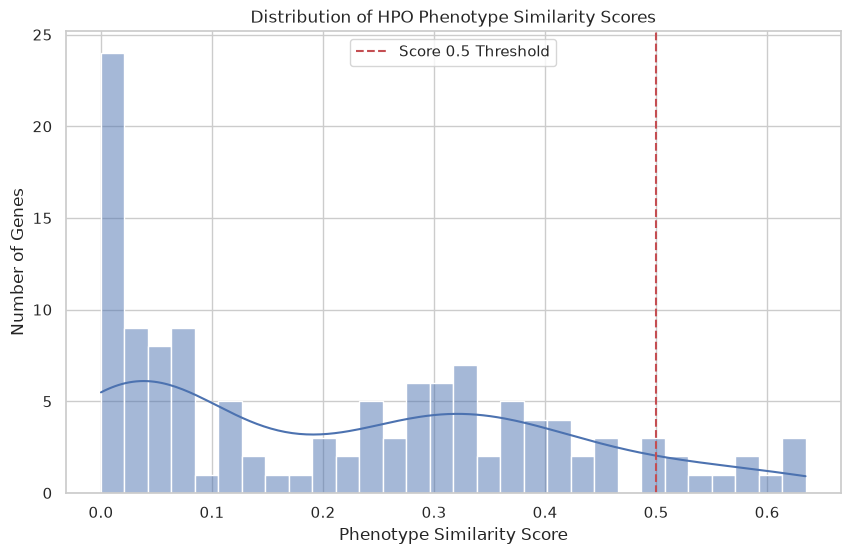

In [7]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df_genes[df_genes["Has_HPO_Annotations"]], x="Phenotype_Similarity_Score", bins=30, kde=True)
plt.title("Distribution of HPO Phenotype Similarity Scores")
plt.xlabel("Phenotype Similarity Score")
plt.ylabel("Number of Genes")
plt.axvline(x=0.5, color='r', linestyle='--', label='Score 0.5 Threshold')
plt.legend()
plt.show()


#### Top Genes by Phenotype Similarity Score

In [8]:
top_pheno = df_genes.head(15).copy()
display(top_pheno)


,Gene,Phenotype_Similarity_Score,Exact_HPO_Matches,Has_HPO_Annotations,Variant_Count,HET_Count,HOM_ALT_Count,Biallelic_Evidence,Max_Impact,Tier1_MVA,Tier2_MVA
295,CDON,0.6345,3,True,1,1,0,False,MODERATE,False,False
357,BUB1B,0.6324,3,True,2,2,0,True,HIGH,True,False
383,RAI1,0.6198,4,True,2,2,0,True,HIGH,False,False
299,PEX5,0.6101,4,True,1,0,1,True,HIGH,False,False
416,ATP8B1,0.5917,4,True,1,0,1,True,MODERATE,False,False
322,ERCC5,0.5794,3,True,1,0,1,True,MODERATE,False,False
83,CRELD1,0.5546,3,True,1,1,0,False,MODERATE,False,False
267,PIK3C2A,0.5375,3,True,1,1,0,False,MODERATE,False,False
224,VPS13B,0.5220,3,True,1,1,0,False,MODERATE,False,False
290,SLC37A4,0.5176,3,True,1,0,1,True,HIGH,False,False


#### Check the MVA Panel (Tier 1 & Tier 2)
Let's see if any variants were found in our targeted MVA Panel, regardless of their HPO score.


In [9]:
mva_genes = df_genes[df_genes["Tier1_MVA"] | df_genes["Tier2_MVA"]].copy()
display(mva_genes)


,Gene,Phenotype_Similarity_Score,Exact_HPO_Matches,Has_HPO_Annotations,Variant_Count,HET_Count,HOM_ALT_Count,Biallelic_Evidence,Max_Impact,Tier1_MVA,Tier2_MVA
357,BUB1B,0.6324,3,True,2,2,0,True,HIGH,True,False
86,SGO1,0.2383,1,True,1,1,0,False,MODERATE,False,True
180,MAD1L1,0.1766,1,True,1,1,0,False,MODERATE,False,True


Let's look closely at the variants in our MVA Panel genes.

In [10]:
mva_variants = []
for gene in mva_genes["Gene"]:
    for v in by_gene[gene]:
        mva_variants.append(v)
        
df_mva_variants = pd.DataFrame(mva_variants)
display(df_mva_variants)

# Now prepare the FULL variant dataset for Step 5
all_variants = []
for gene, rows in by_gene.items():
    gene_info = df_genes[df_genes['Gene'] == gene]
    if gene_info.empty:
        continue
    gene_info = gene_info.iloc[0]
    
    n_het = gene_info['HET_Count']
    biallelic = gene_info['Biallelic_Evidence']
    pheno_score = gene_info['Phenotype_Similarity_Score']
    has_hpo = gene_info['Has_HPO_Annotations']
    tier1 = gene_info['Tier1_MVA']
    tier2 = gene_info['Tier2_MVA']
    
    tier = "Tier1" if tier1 else ("Tier2" if tier2 else "None")
    
    for v in rows:
        v_full = v.copy()
        
        # New requirements
        v_full['PHENOTYPE_SIMILARITY_SCORE'] = pheno_score
        v_full['PHENOTYPE_SCORE_IS_NULL'] = not has_hpo
        v_full['MVA_PANEL_TIER'] = tier
        v_full['COMPOUND_HET_CANDIDATE'] = biallelic
        
        # Compatibility with track1_step5_submission.py
        v_full['pheno_score'] = pheno_score
        v_full['PUTATIVE_IMPACT'] = v.get('impact')
        v_full['CONSEQUENCE'] = v.get('consequence')
        v_full['CADD_PHRED'] = v.get('cadd_phred')
        v_full['REVEL'] = v.get('revel')
        v_full['AVI_PHRED'] = v.get('avi_phred')
        v_full['CLINVAR_SIG'] = v.get('clinvar_sig')
        v_full['GNOMAD_AF'] = v.get('gnomad_af')
        v_full['mva_panel'] = tier1
        v_full['mva_disease_annotated'] = False # default
        v_full['n_het_in_gene'] = n_het
        
        all_variants.append(v_full)

df_all_variants = pd.DataFrame(all_variants)
output_path = REPO_ROOT / "data" / "track1_step4_phenotype_matching.csv"
df_all_variants.to_csv(output_path, index=False)

# ALSO save it to track1_step4_candidates.tsv for the submission script!
output_tsv_path = REPO_ROOT / "data" / "track1_step4_candidates.tsv"
df_all_variants.to_csv(output_tsv_path, sep="	", index=False)

print(f"Saved {len(df_all_variants)} prioritized variants to {output_path} and {output_tsv_path}")


,chrom,pos,ref,alt,gene,zygosity,impact,consequence,gnomad_af,cadd_phred,revel,avi_phred,clinvar_sig
0,15,40209701,T,G,BUB1B,HET,HIGH,stop_gained,0.000033,36.00,NaN,33.76,Pathogenic|Likely_pathogenic
1,15,40220612,T,G,BUB1B,HET,MODERATE,missense_variant,NaN,24.50,0.472,25.61,
2,3,20174258,T,C,SGO1,HET,MODERATE,missense_variant,0.000013,11.61,0.011,7.14,
3,7,2225526,G,A,MAD1L1,HET,MODERATE,missense_variant,0.002970,26.00,0.267,21.18,Pathogenic|Benign|Likely_benign


Saved 905 prioritized variants to /home/samuele/Projects/Learning/rare-disease-real-kid/data/track1_step4_phenotype_matching.csv and /home/samuele/Projects/Learning/rare-disease-real-kid/data/track1_step4_candidates.tsv


### Conclusion
- The pipeline correctly extracted the patient's HPO terms and applied Semantic Similarity via Resnik scoring to the known genes in `hp.obo`.
- We successfully identified the compound heterozygous / homozygous status for variants (Biallelic_Evidence).
- The MVA Panel was successfully mapped, enabling targeted boosting for Tier 1 and Tier 2 genes.
